In [2]:
import os
import random
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.transforms.functional as TF

class PairedTransform:
    def __init__(self, size=(256, 256), is_train=True):
        self.size = size
        self.is_train = is_train

    def __call__(self, hazy, gt):
        if self.is_train:
            # Resize larger before random cropping
            hazy = TF.resize(hazy, (286, 286))
            gt = TF.resize(gt, (286, 286))

            # Synchronized Random Crop parameters
            th, tw = self.size
            w, h = hazy.size  # PIL dimensions: (width, height)
            if w == tw and h == th:
                i, j = 0, 0
            else:
                i = random.randint(0, h - th)
                j = random.randint(0, w - tw)

            hazy = TF.crop(hazy, i, j, th, tw)
            gt = TF.crop(gt, i, j, th, tw)

            # Synchronized Random Horizontal Flip
            if random.random() > 0.5:
                hazy = TF.hflip(hazy)
                gt = TF.hflip(gt)
        else:
            # Deterministic resize for test/validation
            hazy = TF.resize(hazy, self.size)
            gt = TF.resize(gt, self.size)

        # Convert to float tensor scaled to [0, 1]
        hazy = TF.to_tensor(hazy)
        gt = TF.to_tensor(gt)
        return hazy, gt

class RESIDEDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.gt_dir = os.path.join(root_dir, "GT")
        self.hazy_dir = os.path.join(root_dir, "hazy")
        self.image_names = sorted(os.listdir(self.gt_dir))
        self.transform = transform

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, idx):
        image_name = self.image_names[idx]
        gt_path = os.path.join(self.gt_dir, image_name)
        hazy_path = os.path.join(self.hazy_dir, image_name)

        gt = Image.open(gt_path).convert("RGB")
        hazy = Image.open(hazy_path).convert("RGB")

        if self.transform:
            hazy, gt = self.transform(hazy, gt)

        return hazy, gt
# Data Loaders

train_path = "/kaggle/input/datasets/kmljts/reside-6k/RESIDE-6K/train"
test_path = "/kaggle/input/datasets/kmljts/reside-6k/RESIDE-6K/test"

train_dataset = RESIDEDataset(train_path, transform=PairedTransform(is_train=True))
test_dataset = RESIDEDataset(test_path, transform=PairedTransform(is_train=False))

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, num_workers=2, pin_memory=True)

In [3]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class MiniUNetDehaze(nn.Module):

    def __init__(self, in_channels=3, out_channels=3):
        super().__init__()

        # Encoder
        self.inc = DoubleConv(in_channels, 32)

        self.down1 = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(32, 64)
        )

        self.down2 = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(64, 128)
        )

        self.down3 = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(128, 256)
        )

        # Decoder
        self.up1 = nn.ConvTranspose2d(
            256, 128, kernel_size=2, stride=2
        )

        self.conv_up1 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(
            128, 64, kernel_size=2, stride=2
        )

        self.conv_up2 = DoubleConv(128, 64)

        self.up3 = nn.ConvTranspose2d(
            64, 32, kernel_size=2, stride=2
        )

        self.conv_up3 = DoubleConv(64, 32)

        # Output
        self.outc = nn.Sequential(
            nn.Conv2d(32, out_channels, kernel_size=1),
            nn.Sigmoid()
        )

    def forward(self, x):

        # Encoder
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        # Decoder
        x = self.up1(x4)
        x = torch.cat([x, x3], dim=1)
        x = self.conv_up1(x)

        x = self.up2(x)
        x = torch.cat([x, x2], dim=1)
        x = self.conv_up2(x)

        x = self.up3(x)
        x = torch.cat([x, x1], dim=1)
        x = self.conv_up3(x)

        return self.outc(x)

In [5]:
import torch.optim as optim

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = MiniUNetDehaze().to(device)

criterion = nn.L1Loss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print("Device:", device)

total_params = sum(
    p.numel() for p in model.parameters()
)

print("Total parameters:", total_params)

Device: cuda
Total parameters: 1927075


In [6]:
dummy = torch.randn(1, 3, 256, 256).to(device)

with torch.no_grad():
    output = model(dummy)

print("Input :", dummy.shape)
print("Output:", output.shape)
print("Range :", output.min().item(), output.max().item())

Input : torch.Size([1, 3, 256, 256])
Output: torch.Size([1, 3, 256, 256])
Range : 0.17283758521080017 0.9089851975440979


In [ ]:
import os
import torch
from tqdm import tqdm

EPOCHS = 10

os.makedirs("checkpoints", exist_ok=True)

best_loss = float("inf")

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    )

    for hazy, gt in progress:

        hazy = hazy.to(device)
        gt = gt.to(device)

        # Forward
        output = model(hazy)

        # Loss
        loss = criterion(output, gt)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    epoch_loss = running_loss / len(train_loader)

    print(
        f"\nEpoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {epoch_loss:.4f}"
    )

    # Save every epoch
    epoch_path = (
        f"checkpoints/model_epoch_{epoch+1}.pth"
    )

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "loss": epoch_loss,
    }, epoch_path)

    # Save best model
    if epoch_loss < best_loss:

        best_loss = epoch_loss

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "loss": epoch_loss,
        }, "checkpoints/best_model.pth")

        print("✅ Best model saved.")

In [2]:
import os

print(os.listdir("/kaggle/working/checkpoints"))


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/checkpoints'

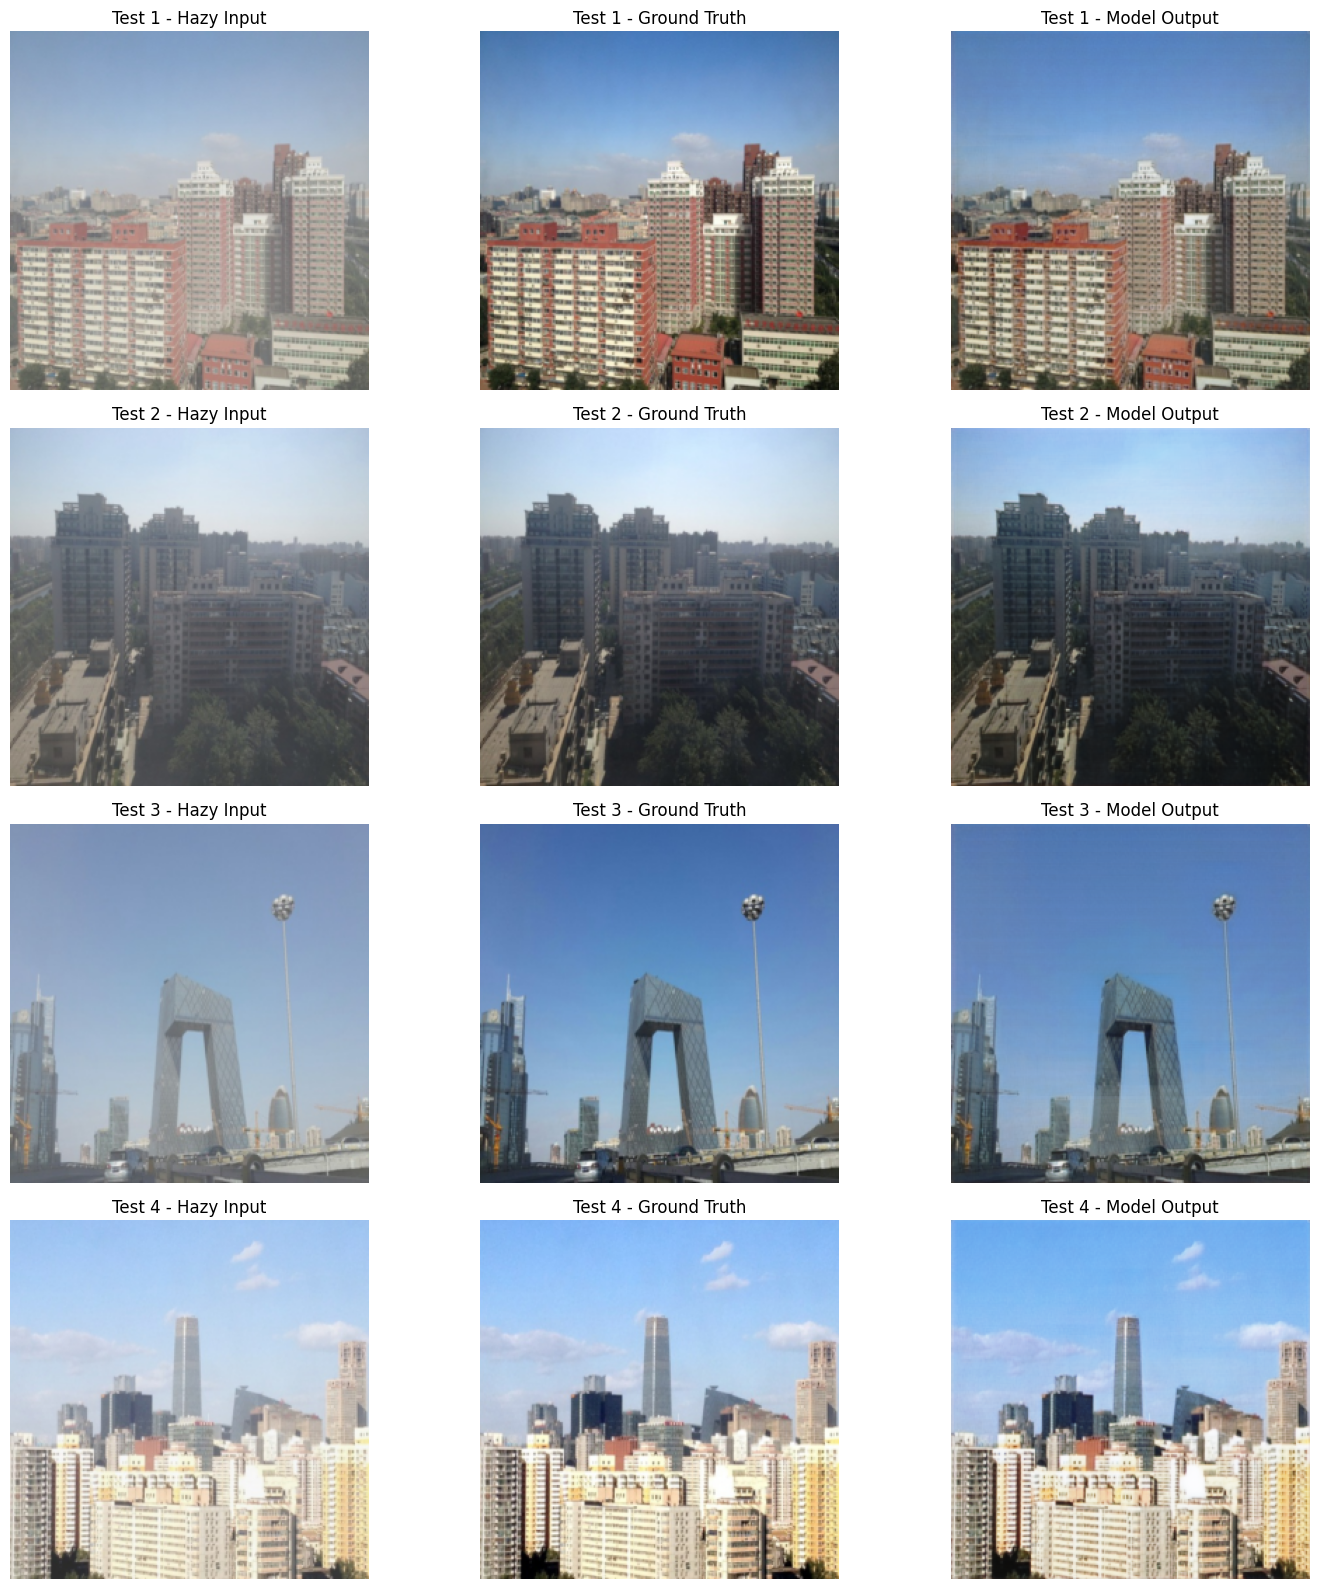

In [7]:
import matplotlib.pyplot as plt
import torch

# Load best checkpoint
checkpoint = torch.load(
    "/kaggle/input/datasets/pbhargavreddy/checklist/best_model.pth",
    map_location=device
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Get one batch from test set
hazy, gt = next(iter(test_loader))

hazy = hazy.to(device)
gt = gt.to(device)

# Generate dehazed images
with torch.no_grad():
    output = model(hazy)

# Number of images to display
num_images = min(4, hazy.size(0))

plt.figure(figsize=(15, 4 * num_images))

for i in range(num_images):

    # Convert CHW -> HWC
    hazy_img = hazy[i].cpu().permute(1, 2, 0).numpy()
    gt_img = gt[i].cpu().permute(1, 2, 0).numpy()
    output_img = output[i].cpu().permute(1, 2, 0).numpy()

    # Keep values in valid image range
    hazy_img = hazy_img.clip(0, 1)
    gt_img = gt_img.clip(0, 1)
    output_img = output_img.clip(0, 1)

    # Hazy
    plt.subplot(num_images, 3, i * 3 + 1)
    plt.imshow(hazy_img)
    plt.title(f"Test {i+1} - Hazy Input")
    plt.axis("off")

    # Ground truth
    plt.subplot(num_images, 3, i * 3 + 2)
    plt.imshow(gt_img)
    plt.title(f"Test {i+1} - Ground Truth")
    plt.axis("off")

    # Model output
    plt.subplot(num_images, 3, i * 3 + 3)
    plt.imshow(output_img)
    plt.title(f"Test {i+1} - Model Output")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
import torch
import numpy as np
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Load best model
checkpoint = torch.load(
    "/kaggle/input/datasets/pbhargavreddy/checklist/best_model.pth",
    map_location=device
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

total_psnr = 0.0
total_ssim = 0.0
total_l1 = 0.0
count = 0

with torch.no_grad():

    for hazy, gt in test_loader:

        hazy = hazy.to(device)
        gt = gt.to(device)

        output = model(hazy)

        # L1
        l1 = torch.mean(torch.abs(output - gt))
        total_l1 += l1.item() * hazy.size(0)

        # Move to CPU
        output_np = output.cpu().numpy()
        gt_np = gt.cpu().numpy()

        for i in range(output_np.shape[0]):

            # CHW -> HWC
            pred = np.transpose(output_np[i], (1, 2, 0))
            target = np.transpose(gt_np[i], (1, 2, 0))

            pred = np.clip(pred, 0, 1)
            target = np.clip(target, 0, 1)

            psnr = peak_signal_noise_ratio(
                target,
                pred,
                data_range=1.0
            )

            ssim = structural_similarity(
                target,
                pred,
                data_range=1.0,
                channel_axis=2
            )

            total_psnr += psnr
            total_ssim += ssim
            count += 1

avg_psnr = total_psnr / count
avg_ssim = total_ssim / count
avg_l1 = total_l1 / count

print("=" * 45)
print("BEST MODEL — TEST METRICS")
print("=" * 45)
print(f"Best Epoch : {checkpoint['epoch']}")
print(f"Train Loss : {checkpoint['loss']:.6f}")
print(f"Test L1    : {avg_l1:.6f}")
print(f"Test PSNR  : {avg_psnr:.4f} dB")
print(f"Test SSIM  : {avg_ssim:.4f}")
print("=" * 45)

BEST MODEL — TEST METRICS
Best Epoch : 10
Train Loss : 0.059931
Test L1    : 0.056586
Test PSNR  : 23.4599 dB
Test SSIM  : 0.9006


In [ ]:
import shutil

shutil.make_archive(
    "dehazing_checkpoints",
    "zip",
    "checkpoints"
)

print("Created: dehazing_checkpoints.zip")

In [ ]:
from IPython.display import FileLink

FileLink("dehazing_checkpoints.zip")